# Phase 4 — Baselines: what can a security team do today without a model?

Every model later has to beat these rules **at the same patching capacity**. All numbers are on the
**validation** set (CVEs published 2024-07-01 → 2024-12-31); train is used only to fix K and, in section 6,
to fit one simple model for the random-split comparison. The test set is not touched.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from metrics import (recall_at_k, recall_curve, random_recall_at_k, rule_at_own_capacity, pr_auc,
                     bootstrap_recall_at_k, ci_table, recall_at_budget)
from description_leak import PHRASES, phrase_flags

FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
BLUE, ORANGE, AQUA, YELLOW, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

dev = pd.read_parquet(ROOT / "data" / "dev.parquet")
train = dev[dev["split"] == "train"].reset_index(drop=True)
val = dev[dev["split"] == "val"].reset_index(drop=True)
for d in (train, val):
    d["phrase_day0"] = phrase_flags(d["description_day0"], PHRASES).any(axis=1)
months_val = val["published"].dt.to_period("M").nunique()
print(f"val: {len(val):,} CVEs over {months_val} months ({len(val) / months_val:,.0f}/month), "
      f"{int(val['label'].sum())} exploited ({val['label'].mean():.2%})")

val: 19,574 CVEs over 6 months (3,262/month), 68 exploited (0.35%)


## 1. The metric: recall@K at a fixed monthly capacity
The team can emergency-patch **K CVEs per month**. Each month we take the K highest-ranked CVEs published that
month; **recall@K** = share of all exploited CVEs that were in someone's top-K. Ties (many CVEs share a CVSS of
9.8) are scored by their expected value under a random tie-break.

**K is fixed from train, before looking at val:** main K = the monthly volume of the current rule
(CVSS ≥ 9 on the CNA's own score) in train; second K = the monthly volume of the *generous* rule
(fallback score incl. later CISA-ADP/NVD scores, Decision 9).

In [2]:
months_tr = train["published"].dt.to_period("M").nunique()
K_MAIN = int(round((train["cvss_cna_score"] >= 9).sum() / months_tr, -1))     # rounded to 10
K_GEN = int(round((train["cvss_score"] >= 9).sum() / months_tr))
KS = [K_MAIN, K_GEN]
print(f"K_MAIN = {K_MAIN}/month (CVSS>=9 CNA in train)  |  K_GEN = {K_GEN}/month (generous fallback CVSS>=9 in train)")
print(f"in val the same rules use {(val['cvss_cna_score'] >= 9).sum() / months_val:.0f} and "
      f"{(val['cvss_score'] >= 9).sum() / months_val:.0f} patches/month (more CVEs, more criticals)")
print(f"K_MAIN = {K_MAIN / (len(val) / months_val):.1%} of val's monthly CVEs; a random pick would catch "
      f"{random_recall_at_k(val, K_MAIN):.1%} of exploited CVEs")

K_MAIN = 110/month (CVSS>=9 CNA in train)  |  K_GEN = 305/month (generous fallback CVSS>=9 in train)
in val the same rules use 196 and 313 patches/month (more CVEs, more criticals)
K_MAIN = 3.4% of val's monthly CVEs; a random pick would catch 3.5% of exploited CVEs


**Takeaway**: K is fixed from train before looking at val: **K = 110 patches/month** (the current CVSS ≥ 9 CNA rule's train volume) and **K = 305** (the generous fallback rule's volume). That is only 3.4% of val's ~3,262 CVEs a month, and a random pick at K = 110 would catch just 3.5% of exploited CVEs. Note that in val the CNA rule itself grew to 196 patches/month, because 2024-H2 had more (and more critical) CVEs, so following the rule literally already overspends the capacity it was sized for.

## 2. The rules at their own capacity (what each rule costs if followed literally)
* **CVSS ≥ 9 (CNA)** — the current rule, day-0 version (Decision 9).
* **CVSS ≥ 7 (CNA)** — the obvious "be safer" alternative.
* **Phrase OR CVSS ≥ 9 (CNA)** — also patch when the publication-day description says the vendor knows of
  exploitation (Decision 10f). A careful team could do this today.
* **Generous CVSS ≥ 9 (fallback)** — uses CISA-ADP/NVD scores that were often added later → an upper bound
  with hindsight, shown for comparison only.

In [3]:
RULES = {
    "CVSS>=9 (CNA)": val["cvss_cna_score"] >= 9,
    "CVSS>=7 (CNA)": val["cvss_cna_score"] >= 7,
    "phrase OR CVSS>=9 (CNA)": val["phrase_day0"] | (val["cvss_cna_score"] >= 9),
    "generous CVSS>=9 (fallback)": val["cvss_score"] >= 9,
}
rng = np.random.default_rng(1)
boots = [rng.poisson(1.0, len(val)) for _ in range(2000)]
rows = []
for name, flag in RULES.items():
    r = rule_at_own_capacity(val, flag)
    rb = [((w * flag * val["label"]).sum() / (w * val["label"]).sum()) for w in boots]
    rows.append({"rule": name, "patches/month": round(r["patches_per_month"]), "caught": r["caught"],
                 "recall_%": round(100 * r["recall"], 1), "recall_95CI": f"{100*np.quantile(rb,.025):.0f}–{100*np.quantile(rb,.975):.0f}",
                 "precision_%": round(100 * r["precision"], 2)})
own = pd.DataFrame(rows).set_index("rule"); display(own)
own.to_csv(TAB / "04_val_rules_own_capacity.csv")

,patches/month,caught,recall_%,recall_95CI,precision_%
rule,,,,,
CVSS>=9 (CNA),196,23,33.8,23–45,1.95
CVSS>=7 (CNA),1089,44,64.7,53–75,0.67
phrase OR CVSS>=9 (CNA),197,26,38.2,26–50,2.20
generous CVSS>=9 (fallback),313,28,41.2,29–53,1.49


**Takeaway**: Followed literally, the current rule (**CVSS ≥ 9, CNA**) patches 196 CVEs/month and catches **33.8%** (23 of 68) of exploited CVEs; precision is only 1.95%. Adding the publication-day phrase check costs **one extra patch per month** (197) and lifts recall to **38.2%**. CVSS ≥ 7 catches 64.7% but needs 1,089 patches/month, 5.6× the budget. The generous fallback rule (41.2% at 313/month) uses hindsight scores and is not available on day 0. With 68 positives, every CI is roughly ±11 points wide.

## 3. Same capacity: recall@K for every rule
At a fixed K a threshold rule becomes a **ranking**: CVSS ≥ 9 and CVSS ≥ 7 both turn into "sort by CNA score"
(CVEs without a CNA score go last). "Phrase OR CVSS" ranks phrase CVEs first, then by CNA score.
Val has only ~68 exploited CVEs, so every number gets a **paired bootstrap 95% CI** (2,000 resamples within
month; same resample for every method, so differences are compared fairly).

In [4]:
SCORES = {
    "CVSS (CNA) ranking": val["cvss_cna_score"].fillna(-1),
    "phrase, then CVSS (CNA)": 100 * val["phrase_day0"] + val["cvss_cna_score"].fillna(-1),
    "generous CVSS (fallback) ranking": val["cvss_score"].fillna(-1),
}
point = {(m, k): recall_at_k(val, s, k) for m, s in SCORES.items() for k in KS}
boot = bootstrap_recall_at_k(val, SCORES, KS, n_boot=2000, seed=0)
ci = ci_table(boot, point)
for k in KS:
    ci.loc[("random", k), ["point", "lo", "hi"]] = [random_recall_at_k(val, k)] * 3
tbl = (ci.mul(100).round(1).reset_index().pivot(index="method", columns="k"))
tbl.columns = [f"{a}@{b}" for a, b in tbl.columns]
tbl = tbl[[f"{c}@{k}" for k in KS for c in ("point", "lo", "hi")]].sort_values(f"point@{K_MAIN}", ascending=False)
display(tbl); tbl.to_csv(TAB / "04_val_recall_at_k_ci.csv")

piv = boot.pivot_table(index=["rep", "k"], columns="method", values="recall")
for other in ["phrase, then CVSS (CNA)", "generous CVSS (fallback) ranking"]:
    for k in KS:
        dlt = (piv[other] - piv["CVSS (CNA) ranking"]).xs(k, level="k") * 100
        print(f"{other} minus CVSS (CNA) @K={k}: {dlt.mean():+.1f} pts, 95% CI {dlt.quantile(.025):+.1f} to "
              f"{dlt.quantile(.975):+.1f}, P(better) = {(dlt > 0).mean():.0%}")

,point@110,lo@110,hi@110,point@305,lo@305,hi@305
method,,,,,,
"phrase, then CVSS (CNA)",28.1,16.9,38.2,42.7,31.2,54.5
CVSS (CNA) ranking,23.7,13.4,33.3,38.3,27.1,50.0
generous CVSS (fallback) ranking,15.1,5.8,25.4,38.5,27.3,50.8
random,3.5,3.5,3.5,9.6,9.6,9.6


phrase, then CVSS (CNA) minus CVSS (CNA) @K=110: +4.3 pts, 95% CI +0.0 to +9.6, P(better) = 94%
phrase, then CVSS (CNA) minus CVSS (CNA) @K=305: +4.4 pts, 95% CI +0.0 to +9.7, P(better) = 95%
generous CVSS (fallback) ranking minus CVSS (CNA) @K=110: -8.1 pts, 95% CI -18.3 to +0.0, P(better) = 2%
generous CVSS (fallback) ranking minus CVSS (CNA) @K=305: +0.6 pts, 95% CI -8.5 to +9.1, P(better) = 51%


**Takeaway**: At the main capacity **K = 110**, ranking by the CNA score catches **23.7%** [13–33] of exploited CVEs, and putting phrase CVEs first raises it to **28.1%** [17–38]: **+4.3 points, better in 94% of bootstrap resamples** (it can only help, since it adds a few certain hits on top of the same ranking). At K = 305 the numbers are 38.3% and 42.7%. Surprisingly, the generous fallback score does **worse** at K = 110 (15.1%): it gives 9.0+ to many more CVEs (313/month), so a 110 budget is spread at random across a big pool of tied 9.8s. **The bar for the models: beat 28.1% at K = 110 and 42.7% at K = 305.**

## 4. Recall vs capacity
How many exploited CVEs does each ranking catch as the monthly budget grows? Dots = each rule followed
literally (section 2); vertical lines = the two capacities fixed in section 1.

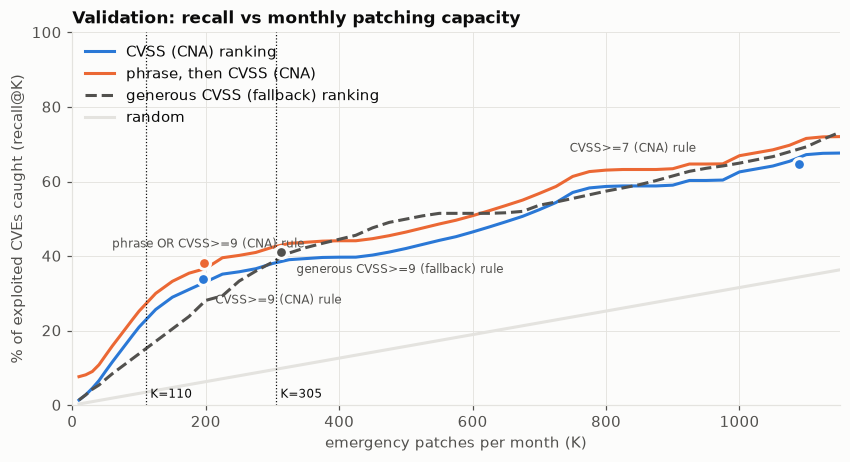

In [5]:
ks = np.unique(np.r_[np.arange(10, 100, 10), np.arange(100, 1151, 25)])
fig, ax = plt.subplots(figsize=(9, 4.4))
styles = {"CVSS (CNA) ranking": BLUE, "phrase, then CVSS (CNA)": ORANGE, "generous CVSS (fallback) ranking": INK2}
curves = {}
for m, s in SCORES.items():
    curves[m] = recall_curve(val, s, ks)
    ax.plot(ks, 100 * curves[m], color=styles[m], lw=2, ls="--" if "generous" in m else "-", label=m)
ax.plot(ks, [100 * random_recall_at_k(val, k) for k in ks], color=GRID, lw=2, label="random")
LABEL_POS = {"CVSS>=9 (CNA)": (8, -16), "CVSS>=7 (CNA)": (-150, 8), "phrase OR CVSS>=9 (CNA)": (-60, 10),
             "generous CVSS>=9 (fallback)": (10, -14)}
for name, color in [("CVSS>=9 (CNA)", BLUE), ("CVSS>=7 (CNA)", BLUE), ("phrase OR CVSS>=9 (CNA)", ORANGE), ("generous CVSS>=9 (fallback)", INK2)]:
    x, y = own.loc[name, "patches/month"], own.loc[name, "recall_%"]
    ax.scatter(x, y, s=60, color=color, zorder=5, edgecolor=SURF, linewidth=2)
    ax.annotate(f"{name} rule", (x, y), fontsize=8, color=INK2, xytext=LABEL_POS[name], textcoords="offset points")
for k in KS:
    ax.axvline(k, color=INK, lw=0.8, ls=":")
    ax.annotate(f"K={k}", (k, 2), fontsize=8, color=INK, xytext=(3, 0), textcoords="offset points")
ax.set_xlabel("emergency patches per month (K)"); ax.set_ylabel("% of exploited CVEs caught (recall@K)")
ax.set_title("Validation: recall vs monthly patching capacity", loc="left"); ax.set_ylim(0, 100); ax.set_xlim(0, 1150)
ax.legend(frameon=False, loc="upper left")
save(fig, "04_01_val_recall_vs_k")

**Takeaway**: All rule curves rise slowly. Doubling the budget from 110 to 220 adds only ~12 points, because CVSS mostly separates *severe* from *mild*, not *exploited* from *not exploited*. Even at 1,000 patches/month (31% of all CVEs) the best rule catches only ~65%. The phrase check helps most at small K, where a handful of vendor-confirmed exploits sit at the very top.

## 5. Where the rules fail
Which exploited CVEs does the best rule still miss at K = K_MAIN? This is the gap a model has to close.

In [6]:
from features import vendor_or_cna
s = SCORES["phrase, then CVSS (CNA)"]
val["_rank_in_month"] = s.groupby(val["published"].dt.to_period("M")).rank(ascending=False, method="average")
miss = val[(val["label"] == 1) & (val["_rank_in_month"] > K_MAIN)].copy()
miss["vendor_key"] = vendor_or_cna(miss)
print(f"exploited CVEs ranked below K={K_MAIN} by 'phrase, then CVSS (CNA)': {len(miss)} of {int(val['label'].sum())}")
print(f"  without any CNA CVSS score: {miss['cvss_cna_score'].isna().sum()}")
print("  top vendors:", miss["vendor_key"].value_counts().head(8).to_dict())
display(miss[["cve_id", "vendor_key", "cvss_cna_score", "cwe", "days_to_kev"]].sort_values("vendor_key").head(15))

exploited CVEs ranked below K=110 by 'phrase, then CVSS (CNA)': 50 of 68
  without any CNA CVSS score: 10
  top vendors: {'microsoft': 17, 'cna:cve@mitre.org': 5, 'palo alto networks': 4, 'google': 3, 'ivanti': 3, 'cisco': 2, 'ptzoptics': 2, 'apache foundation': 1}


,cve_id,vendor_key,cvss_cna_score,cwe,days_to_kev
3365,CVE-2024-38856,apache foundation,NaN,CWE-863,22.0
18560,CVE-2024-12686,beyondtrust,6.6,CWE-78,26.0
67,CVE-2024-20399,cisco,6.0,CWE-78,1.0
11185,CVE-2024-20481,cisco,5.8,CWE-772,1.0
237,CVE-2024-39891,cna:cve@mitre.org,5.3,NVD-CWE-noinfo,21.0
10997,CVE-2024-41713,cna:cve@mitre.org,NaN,NVD-CWE-noinfo,78.0
11521,CVE-2024-50623,cna:cve@mitre.org,NaN,CWE-434,46.0
17258,CVE-2024-55550,cna:cve@mitre.org,NaN,NVD-CWE-noinfo,28.0
18101,CVE-2024-55956,cna:cve@mitre.org,NaN,NVD-CWE-noinfo,4.0
7462,CVE-2024-38813,cna:security@vmware.com,7.5,CWE-250,64.0


**Takeaway**: At K = 110 the best rule still misses **50 of 68** exploited CVEs. 10 of them have **no CNA CVSS score at all** (MITRE-published CVEs, Google Chrome), so a CVSS rule can never rank them. The rest cluster in vendors with a strong exploitation history (**Microsoft 17**, Palo Alto 4, Google 3, Ivanti 3, Cisco 2) and in edge or remote-access products, often with mid-range CVSS (5.8–7.5). Vendor, product type and the description text carry information that CVSS does not, and that is exactly what the models will use.

## 6. Why we split by date: the random-split comparison (run once)
A random stratified split was proposed and rejected (Decision 6). Here we measure what it would have hidden.
One simple model — logistic regression on day-0 tabular features (vendor, CNA, CWE, CNA CVSS parts, phrase
flag; encoders fit inside the Pipeline) — is trained twice with identical settings:
**(a) date split**: train → val; **(b) random split** of the same train+val pool into sets of the same sizes.
Because the random validation set spans 30 months, capacity is expressed as the same **share of each month's
CVEs** (K_MAIN / val CVEs per month). *This is only a preview model; Phase 5 builds and tunes the real ones.*

,model,eval CVEs,eval positives,budget,recall@3.4% of monthly CVEs,PR-AUC,"eval positives with a 'twin' in train (same vendor+month, exploited) %"
split,,,,,,,
date split (train -> val),"preview LR (C=0.1, balanced)",19574,68,3.37% of each month's CVEs,38.2,0.108,0.0
random split,"preview LR (C=0.1, balanced)",19574,67,3.37% of each month's CVEs,59.1,0.126,50.7


Budget note: 3.37% of each month's CVEs = 110 on an average val month, but busier months get more slots.
Same preview LR on the date split with a flat budget: recall@110/month = 36.8%, recall@305/month = 67.6%  (vs 38.2% with the share-of-month budget)


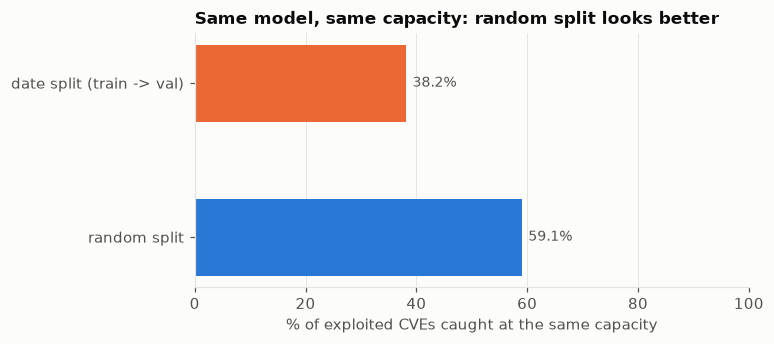

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from features import day0_tabular, CATEGORICAL, NUMERIC

def make_lr():
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), CATEGORICAL),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(class_weight="balanced", C=0.1, max_iter=3000))])

FRAC = K_MAIN / (len(val) / months_val)
pool = pd.concat([train, val], ignore_index=True)
Xpool = day0_tabular(pool)
res = {}
# (a) date split
is_tr = pool["split"].eq("train").to_numpy()
m = make_lr().fit(Xpool[is_tr], pool.loc[is_tr, "label"])
ev = pool[~is_tr].copy(); ev["p"] = m.predict_proba(Xpool[~is_tr])[:, 1]
res["date split (train -> val)"] = ev
# (b) random stratified split, same sizes
idx_tr, idx_ev = train_test_split(np.arange(len(pool)), test_size=len(val), stratify=pool["label"], random_state=42)
m2 = make_lr().fit(Xpool.iloc[idx_tr], pool.loc[idx_tr, "label"])
ev2 = pool.iloc[idx_ev].copy(); ev2["p"] = m2.predict_proba(Xpool.iloc[idx_ev])[:, 1]
res["random split"] = ev2

def twins(train_part, eval_part):
    key = lambda d: vendor_or_cna(d) + "|" + d["published"].dt.strftime("%Y-%m")
    pos_keys = set(key(train_part[train_part["label"] == 1]))
    e = eval_part[eval_part["label"] == 1]
    return key(e).isin(pos_keys).mean()

rows = []
for name, ev_ in res.items():
    trp = pool[is_tr] if name.startswith("date") else pool.iloc[idx_tr]
    rows.append({"split": name, "model": "preview LR (C=0.1, balanced)", "eval CVEs": len(ev_),
                 "eval positives": int(ev_["label"].sum()),
                 "budget": f"{FRAC:.2%} of each month's CVEs",
                 f"recall@{FRAC:.1%} of monthly CVEs": round(100 * recall_at_budget(ev_, "p", FRAC), 1),
                 "PR-AUC": round(pr_auc(ev_, "p"), 3),
                 "eval positives with a 'twin' in train (same vendor+month, exploited) %": round(100 * twins(trp, ev_), 1)})
rs = pd.DataFrame(rows).set_index("split"); display(rs); rs.to_csv(TAB / "04_random_vs_date_split.csv")
LR_DATE_R110 = recall_at_k(res["date split (train -> val)"], "p", K_MAIN)
LR_DATE_R306 = recall_at_k(res["date split (train -> val)"], "p", K_GEN)
print(f"Budget note: {FRAC:.2%} of each month's CVEs = {K_MAIN} on an average val month, but busier months get more slots.")
print(f"Same preview LR on the date split with a flat budget: recall@{K_MAIN}/month = {LR_DATE_R110:.1%}, "
      f"recall@{K_GEN}/month = {LR_DATE_R306:.1%}  (vs {recall_at_budget(res['date split (train -> val)'], 'p', FRAC):.1%} "
      f"with the share-of-month budget)")

fig, ax = plt.subplots(figsize=(6.5, 3))
col = f"recall@{FRAC:.1%} of monthly CVEs"
ax.barh(rs.index[::-1], rs[col][::-1], color=[BLUE, ORANGE], height=0.5)
for y, v in enumerate(rs[col][::-1]):
    ax.annotate(f"{v:.1f}%", (v, y), va="center", fontsize=9, color=INK2, xytext=(4, 0), textcoords="offset points")
ax.set_xlim(0, 100); ax.set_xlabel("% of exploited CVEs caught at the same capacity"); ax.grid(axis="y", visible=False)
ax.set_title("Same model, same capacity: random split looks better", loc="left")
save(fig, "04_02_random_vs_date_split")

**Takeaway**: The **same** preview logistic regression (C = 0.1, balanced weights) at the **same** budget (3.37% of each month's CVEs, the share-of-month equivalent of K = 110, needed because the random evaluation set spans 30 months) catches **38.2%** of exploited CVEs on the honest date split but **59.1%** on a random split. With the flat 110/month budget the date-split figure is 36.8%, the number used in the comparison table: **+21 points of pure illusion**. The reason is visible in the last column: on the random split **51% of the evaluation positives have an exploited 'twin' in training** (same vendor, same month, often the same patch-day bulletin or exploit chain), and the model simply recognises them. On the date split that number is 0%. PR-AUC hides most of the gap (0.108 vs 0.126), which is one more reason we select on recall@K. Even this untuned preview already beats the best rule at K = 110 (36.8% vs 28.1%).

## 7. Comparison table (validation) — all methods so far

In [8]:
rows = []
own_map = {"CVSS (CNA) ranking": "CVSS>=9 (CNA)", "phrase, then CVSS (CNA)": "phrase OR CVSS>=9 (CNA)",
           "generous CVSS (fallback) ranking": "generous CVSS>=9 (fallback)"}
def fmt(m, k):
    r = ci.loc[(m, k)]
    return f"{100*r['point']:.1f} [{100*r['lo']:.0f}–{100*r['hi']:.0f}]" if r["lo"] != r["hi"] else f"{100*r['point']:.1f}"
for m in ["random", "CVSS (CNA) ranking", "phrase, then CVSS (CNA)", "generous CVSS (fallback) ranking"]:
    o = own.loc[own_map[m]] if m in own_map else None
    rows.append({"method": m, "type": "benchmark" if "generous" not in m else "benchmark (hindsight, upper bound)",
                 "rule patches/month": "" if o is None else int(o["patches/month"]),
                 "rule recall %": "" if o is None else o["recall_%"],
                 f"recall@{K_MAIN} % [95% CI]": fmt(m, K_MAIN), f"recall@{K_GEN} % [95% CI]": fmt(m, K_GEN),
                 "PR-AUC": "" if m == "random" else round(pr_auc(val, SCORES[m]), 3)})
rows.append({"method": "CVSS>=7 (CNA) rule", "type": "benchmark", "rule patches/month": int(own.loc["CVSS>=7 (CNA)", "patches/month"]),
             "rule recall %": own.loc["CVSS>=7 (CNA)", "recall_%"], f"recall@{K_MAIN} % [95% CI]": "= CVSS (CNA) ranking",
             f"recall@{K_GEN} % [95% CI]": "= CVSS (CNA) ranking", "PR-AUC": ""})
rows.append({"method": "preview: logistic regression (day-0 tabular)", "type": "model preview (Phase 5)",
             "rule patches/month": "", "rule recall %": "", f"recall@{K_MAIN} % [95% CI]": f"{100*LR_DATE_R110:.1f}",
             f"recall@{K_GEN} % [95% CI]": f"{100*LR_DATE_R306:.1f}", "PR-AUC": round(pr_auc(res['date split (train -> val)'], 'p'), 3)})
comp = pd.DataFrame(rows).set_index("method"); display(comp); comp.to_csv(TAB / "04_val_comparison.csv")

,type,rule patches/month,rule recall %,recall@110 % [95% CI],recall@305 % [95% CI],PR-AUC
method,,,,,,
random,benchmark,,,3.5,9.6,
CVSS (CNA) ranking,benchmark,196,33.8,23.7 [13–33],38.3 [27–50],0.011
"phrase, then CVSS (CNA)",benchmark,197,38.2,28.1 [17–38],42.7 [31–55],0.069
generous CVSS (fallback) ranking,"benchmark (hindsight, upper bound)",313,41.2,15.1 [6–25],38.5 [27–51],0.011
CVSS>=7 (CNA) rule,benchmark,1089,64.7,= CVSS (CNA) ranking,= CVSS (CNA) ranking,
preview: logistic regression (day-0 tabular),model preview (Phase 5),,,36.8,67.6,0.108


**Takeaway**: On validation, the best day-0 rule a careful team could follow today is **'phrase, then CVSS (CNA)'**: **28.1%** of exploited CVEs at 110 patches/month and **42.7%** at 305. The generous fallback is no better at K = 110 and uses hindsight. An untuned logistic regression on day-0 tabular features already reaches **36.8% / 67.6%**, a first sign that a model can roughly double what CVSS catches at the same capacity. The wide CIs (±10 points) from only 68 positives mean Phase 5 should also lean on grouped CV inside train and the walk-forward folds, not on val alone.